# 07. 가격 전망·저평가 모델 (법정동 단위)
변수: 출퇴근시간, 학원가 여부(학원 140개 이상 동), 급지, 금리.
1. 횡단면 모형: 변수들로 설명되는 적정가격 대비 실제가격 → **저평가 동 선정**. 여기에 **1~3급지 동의 ㎡당 가격 - 바로 아래 급지 ㎡당 평균가**(02번 하위→상위 선행관계에 근거, 차이가 작을수록 저평가)를 더한 종합점수
2. 금리 반응 모형: 동 특성별 금리 민감도
3. 백테스트: 저평가 지표가 이후 12개월 상대 상승을 예측했는지
4. 시나리오: 금리·출퇴근시간·학원가·급지를 바꿨을 때 12개월 가격 변화

출퇴근시간은 `data/05_직주근접/동별_업무지구_대중교통시간_구글.csv`(출발 08:00, 광화문·강남·여의도) 중 최단 시간을 쓴다. 이 파일에 없는 동은 같은 구 평균으로 채운다. 단지 좌표 직선거리 기반 추정치는 비교용으로만 계산한다.
학원 수와 출퇴근시간은 현재 시점 값이라 과거 시점에도 동일하다고 가정한다. 결과는 연관성이며 인과효과가 아니다.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import display
root = next(p for p in [Path.cwd(), Path.cwd().parent] if (p/'data').is_dir())
out = root/'outputs'/'07_model'
out.mkdir(parents=True, exist_ok=True)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
pd.set_option('display.max_columns', 30)
import unicodedata
def find(d, prefix, ext=''):
    return next(p for p in sorted(Path(d).iterdir()) if unicodedata.normalize('NFC', p.name).startswith(prefix) and p.name.lower().endswith(ext))
def save(frame, name): frame.to_csv(out/(name+'.csv'), index=False, encoding='utf-8-sig')

ACADEMY_MIN = 140          # 학원가 기준: 동 내 학원·교습소 수
MIN_TRADES_Q = 10          # 동×분기 지수 최소 거래수
MIN_TRADES_WIN = 40        # 저평가 판정 대상: 최근 4분기 거래수
CBD = {'도심': (37.5663, 126.9779), 'GBD': (37.4979, 127.0276), 'YBD': (37.5215, 126.9243)}

## 1. 실거래 정제

In [2]:
raw = pd.read_excel(root/'data'/'서울_아파트_매매_실거래가_2017-2026_통합.xlsx', dtype=str)
raw.columns = raw.columns.str.strip()
for c in raw: raw[c] = raw[c].astype('string').str.strip()
def num(s): return pd.to_numeric(s.str.replace(',', '', regex=False), errors='coerce')
df = pd.DataFrame({
    '가격': num(raw['거래금액(만원)']), '면적': num(raw['전용면적(㎡)']), '층': num(raw['층']), '건축년도': num(raw['건축년도']),
    '날짜': pd.to_datetime(raw['계약년월']+raw['계약일'].str.zfill(2), format='%Y%m%d', errors='coerce'),
    '구': raw['시군구'].str.extract(r'^서울특별시\s+(\S+구)', expand=False),
    '동': raw['시군구'].str.split().str[-1], '유형': raw['주택유형'], '해제': raw['해제사유발생일'].fillna('')})
ok = df['구'].notna() & df['유형'].eq('아파트') & df['날짜'].notna() & df['가격'].gt(0) & df['면적'].gt(0) & df['해제'].isin(['', '-', '0'])
df = df[ok.fillna(False)].drop(columns=['유형', '해제']).copy()
df['분기'] = df['날짜'].dt.to_period('Q').dt.to_timestamp()
df = df[(df['분기'] >= '2018-01-01') & (df['분기'] <= '2026-07-01')]     # 부분 분기(2017Q4, 2026Q4) 제외
df['로그가격'] = np.log(df['가격']/df['면적'])
df['동키'] = df['구'] + ' ' + df['동']
print(f'{len(df):,}건 | {df["분기"].min().year}Q{df["분기"].min().quarter} ~ {df["분기"].max().year}Q{df["분기"].max().quarter}')

510,544건 | 2018Q1 ~ 2026Q3


## 2. 동별 특성: 학원가, 급지, 출퇴근시간

In [3]:
# 학원가: 상세주소 괄호 안의 법정동으로 집계
aca = pd.read_csv(root/'data'/'04_교육'/'학원교습소정보.csv', low_memory=False)
dn = aca['도로명상세주소'].fillna('').str.extract(r'\(([^)]*)\)')[0].fillna('').str.split(',').str[0].str.strip()
aca['동'] = dn.str.extract(r'([가-힣]+\d*(?:동|가))$', expand=False)
aca_cnt = aca.dropna(subset=['동']).groupby(['행정구역명', '동']).size().rename('학원수').reset_index()
aca_cnt['동키'] = aca_cnt['행정구역명'] + ' ' + aca_cnt['동']
print(f'동 추출률 {aca["동"].notna().mean():.1%} | 학원수≥{ACADEMY_MIN}인 동 {int((aca_cnt["학원수"] >= ACADEMY_MIN).sum())}개')

# 급지: 02번 K-means(k=4) 주분석
grp = pd.read_csv(root/'outputs'/'02_analysis'/'district_groups.csv')
tier = grp.set_index('자치구')['주분석급지'].str.extract(r'(\d)')[0].astype(int)

# 출퇴근시간 비교용 추정: 단지 좌표 → 3대 업무지구 최단 (직선거리×1.3 / 30km/h + 역 도보 + 대기 8분)
apt = pd.read_csv(find(root/'data'/'05_직주근접', '아파트 좌표정보', '.csv'), encoding='cp949')
apt = apt.dropna(subset=['좌표X', '좌표Y']).rename(columns={'주소(시군구)': '구', '주소(읍면동)': '동'})
sub = pd.read_csv(root/'data'/'05_직주근접'/'지하철역 좌표정보.csv')
def hav(lat1, lon1, lat2, lon2):
    p = np.pi/180
    a = np.sin((lat2-lat1)*p/2)**2 + np.cos(lat1*p)*np.cos(lat2*p)*np.sin((lon2-lon1)*p/2)**2
    return 12742*np.arcsin(np.sqrt(a))
lat, lon = apt['좌표Y'].to_numpy()[:, None], apt['좌표X'].to_numpy()[:, None]
st_km = hav(lat, lon, sub['환승역Y좌표'].to_numpy()[None, :], sub['환승역X좌표'].to_numpy()[None, :]).min(axis=1)
to_cbd = np.min([hav(apt['좌표Y'].to_numpy(), apt['좌표X'].to_numpy(), la, lo) for la, lo in CBD.values()], axis=0)
apt['통근분'] = 8 + st_km*1000/80 + to_cbd*1.3/30*60
commute = apt.groupby(['구', '동'])['통근분'].agg(['mean', 'size']).reset_index().rename(columns={'mean': '통근분', 'size': '단지수'})
commute['동키'] = commute['구'] + ' ' + commute['동']
api_file = find(root/'data'/'05_직주근접', '동별_업무지구_대중교통시간', '.csv')
api = pd.read_csv(api_file)
api['동키'] = api['동키'].map(lambda x: unicodedata.normalize('NFC', x))
api_min = api.groupby('동키')['분'].min().rename('통근분_api')     # 3대 업무지구(광화문·강남·여의도) 중 최단 대중교통 시간
chk = commute.merge(api_min, on='동키')
print(f'대중교통 API: 동 {len(api_min)}개 | 직선거리 추정치와 상관 {chk["통근분"].corr(chk["통근분_api"]):.2f}')
commute = commute[['동키']].merge(api_min.rename('통근분'), on='동키', how='outer')


traits = df.groupby(['구', '동', '동키']).size().rename('거래수').reset_index()
traits = traits.merge(aca_cnt[['동키', '학원수']], on='동키', how='left').merge(commute[['동키', '통근분']], on='동키', how='left')
traits['학원수'] = traits['학원수'].fillna(0)
traits['학원가'] = (traits['학원수'] >= ACADEMY_MIN).astype(float)
traits['급지'] = traits['구'].map(tier)
n_miss = traits['통근분'].isna().sum()
traits['통근분'] = traits['통근분'].fillna(traits.groupby('구')['통근분'].transform('mean'))
traits = traits.dropna(subset=['통근분', '급지'])
print(f'동 {len(traits)}개 (통근시간이 구 평균으로 대체된 동 {n_miss}개)')
save(traits, 'dong_traits')
display(traits.groupby('급지')[['통근분', '학원가']].mean())

동 추출률 93.4% | 학원수≥140인 동 49개
대중교통 API: 동 276개 | 직선거리 추정치와 상관 0.85
동 338개 (통근시간이 구 평균으로 대체된 동 62개)


,통근분,학원가
급지,,
1,26.852,0.455
2,23.886,0.071
3,22.106,0.119
4,38.008,0.182


## 3. 동×분기 구성보정 가격지수
면적·연식·층을 통제(FWL)한 동×분기 로그 ㎡당 가격.

In [4]:
age = (df['분기'].dt.year - df['건축년도']).clip(lower=0, upper=60)
ctrl = pd.concat([
    pd.get_dummies(pd.cut(df['면적'], [0, 40, 60, 85, 102, 135, 1e4]).astype(str), prefix='a', drop_first=True),
    pd.get_dummies(pd.cut(age, [-1, 5, 10, 15, 20, 25, 30, 100]).astype(str), prefix='b', drop_first=True),
    pd.get_dummies(pd.cut(df['층'], [-100, 2, 5, 10, 15, 20, 200]).astype(str), prefix='c', drop_first=True),
], axis=1).astype(float)
key = df['동키'] + '|' + df['분기'].dt.strftime('%Y-%m')
y = df['로그가격']
beta = np.linalg.lstsq((ctrl - ctrl.groupby(key).transform('mean')).to_numpy(),
                       (y - y.groupby(key).transform('mean')).to_numpy(), rcond=None)[0]
adj = y - ctrl.to_numpy() @ beta
cell = adj.groupby([df['동키'], df['분기']]).agg(['mean', 'size'])
cell.columns = ['idx', 'n']
cell.loc[cell['n'] < MIN_TRADES_Q, 'idx'] = np.nan
Q = pd.date_range(df['분기'].min(), df['분기'].max(), freq='QS')
idxq = cell['idx'].unstack(0).reindex(Q)[traits['동키']]
nq = cell['n'].unstack(0).reindex(Q).reindex(columns=traits['동키']).fillna(0)
print(f'분기 {len(Q)}개 | 동 {idxq.shape[1]}개 | 유효 동-분기 {int(idxq.notna().sum().sum()):,}')

분기 35개 | 동 338개 | 유효 동-분기 6,324


## 4. 횡단면 모형: 적정가격과 저평가
최근 4분기 평균 로그가격 ~ 출퇴근시간 + 학원가 + 급지. 표준오차는 구 군집. 잔차가 음수면 같은 조건 대비 저평가.

In [5]:
def cluster_ols(X, y, g):
    X = np.asarray(X, float); y = np.asarray(y, float)
    XtXi = np.linalg.pinv(X.T @ X)
    b = XtXi @ X.T @ y
    u = y - X @ b
    S = sum(np.outer(X[g == k].T @ u[g == k], X[g == k].T @ u[g == k]) for k in np.unique(g))
    G, n, p = len(np.unique(g)), len(y), X.shape[1]
    V = XtXi @ S @ XtXi * (G/(G-1)) * ((n-1)/(n-p))
    return b, np.sqrt(np.diag(V)), G-1

XCOLS = ['통근분', '학원가', '급지2', '급지3', '급지4']
def design_x(t):
    X = pd.DataFrame({'const': 1.0, '통근분': t['통근분'].to_numpy(), '학원가': t['학원가'].to_numpy()}, index=t.index)
    for k in (2, 3, 4): X[f'급지{k}'] = (t['급지'] == k).astype(float).to_numpy()
    return X

def level_at(q, win=4, min_valid=3):
    sl = idxq.loc[:q].iloc[-win:]
    L = sl.mean()
    L[sl.notna().sum() < min_valid] = np.nan
    return L, nq.loc[:q].iloc[-win:].sum()

def xsection(q):
    L, n = level_at(q)
    t = traits.set_index('동키').assign(L=L, n=n)
    t = t[t['L'].notna() & (t['n'] >= MIN_TRADES_WIN)]
    X = design_x(t)
    b, se, df_ = cluster_ols(X, t['L'], t['구'].to_numpy())
    fit_ = X.to_numpy() @ b
    t = t.assign(적정로그가격=fit_, 괴리=t['L'] - fit_)
    return t, pd.DataFrame({'계수': b, '표준오차': se, 'p값': 2*stats.t.sf(np.abs(b/se), df_)}, index=X.columns)

def lower_gap_scores(t):
    # 1~3급지: 동의 ㎡당 가격 - 바로 아래 급지 동들의 ㎡당 평균가(거래수 가중). 작을수록 저평가. 4급지는 정의 불가(NaN).
    price = np.exp(t['L'])
    gap = pd.Series(np.nan, index=t.index); bench = pd.Series(np.nan, index=t.index)
    for k in (1, 2, 3):
        m, low = t['급지'] == k, t['급지'] == k+1
        if m.any() and low.any():
            b = np.average(price[low], weights=t.loc[low, 'n'])
            bench[m], gap[m] = b, price[m] - b
    gz = gap.groupby(t['급지']).transform(lambda s_: (s_ - s_.mean())/s_.std())      # 급지 내 z (낮을수록 저평가)
    zg = t['괴리']/t['괴리'].std()
    comp = zg.where(gz.isna(), (zg + gz)/2)                                       # 종합 = 괴리z와 격차z 평균 (4급지는 괴리z)
    return pd.DataFrame({'하위급지평균가': bench, '하위급지격차': gap, '격차z': gz, '종합z': comp})

q_last = Q[-1]
cs, cs_coef = xsection(q_last)
r2 = 1 - ((cs['L']-cs['적정로그가격'])**2).sum()/((cs['L']-cs['L'].mean())**2).sum()
cs_show = cs_coef.copy(); cs_show['가격영향_%'] = (np.exp(cs_coef['계수'])-1)*100
display(cs_show)
print(f'기준 {q_last:%Y}Q{q_last.quarter} 직전 4분기 | 동 {len(cs)}개 | R²={r2:.3f}')
print('통근시간 10분당 가격 차이: ', f"{(np.exp(cs_coef.loc['통근분','계수']*10)-1)*100:+.1f}%")
save(cs_show.rename_axis('변수').reset_index(), 'cross_section_coefs')

,계수,표준오차,p값,가격영향_%
const,8.266,0.104,0.000,"388,770.669"
통근분,-0.008,0.002,0.004,-0.756
학원가,0.054,0.047,0.263,5.529
급지2,-0.311,0.110,0.009,-26.751
급지3,-0.610,0.100,0.000,-45.646
급지4,-0.898,0.111,0.000,-59.258


기준 2026Q3 직전 4분기 | 동 191개 | R²=0.683
통근시간 10분당 가격 차이:  -7.3%


In [6]:
res = cs.reset_index()[['동키', '구', '동', '급지', '통근분', '학원수', '학원가', 'n', 'L', '적정로그가격', '괴리']]
res['실제㎡당가격_만원'] = np.exp(res['L'])
res['적정㎡당가격_만원'] = np.exp(res['적정로그가격'])
res['괴리_%'] = (np.exp(res['괴리'])-1)*100          # 음수 = 저평가
res['괴리_z'] = res['괴리']/res['괴리'].std()
res = res.merge(lower_gap_scores(cs).reset_index(), on='동키')
res = res.sort_values('괴리_%')
save(res, 'undervalued_dong')
cols = ['구', '동', '급지', '통근분', '학원수', '실제㎡당가격_만원', '적정㎡당가격_만원', '괴리_%', 'n']
print('저평가 상위 15개 동 (같은 통근·학원가·급지 조건 대비)')
display(res[cols].head(15).reset_index(drop=True))
print('고평가 상위 10개 동')
display(res[cols].tail(10).iloc[::-1].reset_index(drop=True))
print('종합 저평가 상위 15개 동 (적정가격 괴리 + 하위급지와의 ㎡당 가격차이, 낮을수록 저평가)')
ccols = ['구', '동', '급지', '실제㎡당가격_만원', '하위급지평균가', '하위급지격차', '괴리_%', '종합z']
display(res.sort_values('종합z')[ccols].head(15).reset_index(drop=True))
gu_gap = res.groupby('구').apply(lambda d: pd.Series({'평균괴리_%': np.average(d['괴리_%'], weights=d['n']), '동수': len(d)})).sort_values('평균괴리_%')
save(gu_gap.reset_index(), 'undervalued_gu')
print('자치구별 평균 괴리(거래수 가중)')
display(gu_gap)

저평가 상위 15개 동 (같은 통근·학원가·급지 조건 대비)


,구,동,급지,통근분,학원수,실제㎡당가격_만원,적정㎡당가격_만원,괴리_%,n
0,서대문구,홍은동,3,26.900,104.000,"1,058.881","1,723.240",-38.553,502
1,마포구,망원동,2,27.200,55.000,"1,437.292","2,316.980",-37.967,182
2,서초구,양재동,1,30.517,93.000,"1,954.162","3,084.512",-36.646,93
3,서초구,서초동,1,9.950,481.000,"2,413.859","3,805.137",-36.563,747
4,양천구,신월동,3,34.367,226.000,"1,106.787","1,718.299",-35.588,803
5,마포구,서교동,2,15.133,121.000,"1,662.491","2,539.266",-34.529,56
6,강남구,역삼동,1,11.300,344.000,"2,483.560","3,766.337",-34.059,320
7,광진구,중곡동,3,34.300,117.000,"1,098.501","1,629.096",-32.570,133
8,종로구,숭인동,3,24.600,12.000,"1,188.868","1,753.595",-32.204,85
9,도봉구,쌍문동,4,53.733,197.000,754.129,"1,111.871",-32.175,525


고평가 상위 10개 동


,구,동,급지,통근분,학원수,실제㎡당가격_만원,적정㎡당가격_만원,괴리_%,n
0,강남구,압구정동,1,27.167,36.000,"7,155.223","3,163.967",126.147,168
1,영등포구,여의도동,3,15.450,104.000,"3,446.746","1,879.742",83.363,232
2,송파구,잠실동,2,16.917,260.000,"4,741.069","2,643.628",79.340,783
3,광진구,광장동,3,34.050,95.000,"2,659.175","1,632.191",62.921,208
4,송파구,신천동,2,19.700,117.000,"3,878.307","2,452.738",58.122,368
5,용산구,이촌동,2,25.067,43.000,"3,644.017","2,354.812",54.748,276
6,강동구,고덕동,3,48.600,163.000,"2,366.967","1,542.301",53.470,345
7,구로구,신도림동,4,33.883,102.000,"1,872.810","1,224.987",52.884,484
8,강동구,명일동,3,47.650,324.000,"2,234.634","1,553.465",43.848,326
9,동작구,흑석동,3,12.683,64.000,"2,745.629","1,919.643",43.028,189


종합 저평가 상위 15개 동 (적정가격 괴리 + 하위급지와의 ㎡당 가격차이, 낮을수록 저평가)


,구,동,급지,실제㎡당가격_만원,하위급지평균가,하위급지격차,괴리_%,종합z
0,서대문구,홍은동,3,"1,058.881","1,202.401",-143.520,-38.553,-1.863
1,마포구,망원동,2,"1,437.292","1,738.223",-300.931,-37.967,-1.825
2,양천구,신월동,3,"1,106.787","1,202.401",-95.614,-35.588,-1.710
3,도봉구,쌍문동,4,754.129,NaN,NaN,-32.175,-1.681
4,광진구,중곡동,3,"1,098.501","1,202.401",-103.899,-32.570,-1.619
5,서초구,양재동,1,"1,954.162","2,641.869",-687.707,-36.646,-1.591
6,강서구,공항동,3,"1,136.842","1,202.401",-65.559,-31.442,-1.542
7,은평구,구산동,4,815.140,NaN,NaN,-29.799,-1.532
8,마포구,서교동,2,"1,662.491","1,738.223",-75.732,-34.529,-1.529
9,종로구,숭인동,3,"1,188.868","1,202.401",-13.533,-32.204,-1.510


자치구별 평균 괴리(거래수 가중)


,평균괴리_%,동수
구,,
도봉구,-18.474,4.000
종로구,-17.572,3.000
강서구,-16.210,8.000
금천구,-15.522,3.000
서초구,-12.813,6.000
마포구,-12.576,14.000
서대문구,-12.389,9.000
강북구,-4.997,3.000
중랑구,-4.448,6.000


## 5. 금리 반응 모형 (동×분기 패널, 2018Q1~2024Q2)
`분기 가격변화(%) = 동 고정효과 + Δ금리(t, t-1) × (1, 급지, 학원가, 출퇴근시간) + 전분기 상승률 + 정책분기 더미`.
금리는 CD수익률 분기평균의 변화(%p). 표준오차는 분기 단위 Driscoll–Kraay(시차 2).

In [7]:
rate_raw = pd.read_csv(next(p for p in (root/'data'/'06_정책').iterdir() if '시장금리' in unicodedata.normalize('NFC', p.name) and p.suffix == '.csv'), encoding='cp949')
rate_raw['날짜'] = pd.to_datetime(rate_raw['기준일자'])
rate_raw['금리'] = pd.to_numeric(rate_raw['고시금리'], errors='coerce')
rate_last_q = (rate_raw['날짜'].max().to_period('Q').to_timestamp() - pd.DateOffset(months=3))   # 완결 분기
cd = rate_raw[rate_raw['시장금리종류'].eq('CD수익률')].groupby('날짜')['금리'].mean().resample('QS').mean()
dr = cd.diff()
events = pd.read_csv(root/'outputs'/'06_policy'/'event_calendar.csv', parse_dates=['월'])
evq = pd.DatetimeIndex(events['월']).to_period('Q').to_timestamp()
pol = pd.Series(Q.isin(evq) | Q.isin(evq + pd.DateOffset(months=3)), index=Q).astype(float)

dY = idxq.diff()*100
zc = (traits.set_index('동키')['통근분'] - traits['통근분'].mean())/traits['통근분'].std()
rows = []
for k in traits['동키']:
    d = pd.DataFrame({'y': dY[k], 'mom': dY[k].shift(1), 'pol': pol, 'dr0': dr.reindex(Q), 'dr1': dr.shift(1).reindex(Q)})
    d['동키'], d['t'] = k, np.arange(len(d))
    rows.append(d)
P = pd.concat(rows).rename_axis('분기').reset_index().dropna()
P = P[P['분기'] <= rate_last_q]
T = traits.set_index('동키')
for lag in ('dr0', 'dr1'):
    P[f'{lag}_급지2'] = P[lag]*(P['동키'].map(T['급지']) == 2)
    P[f'{lag}_급지3'] = P[lag]*(P['동키'].map(T['급지']) == 3)
    P[f'{lag}_급지4'] = P[lag]*(P['동키'].map(T['급지']) == 4)
    P[f'{lag}_학원가'] = P[lag]*P['동키'].map(T['학원가'])
    P[f'{lag}_통근z'] = P[lag]*P['동키'].map(zc)
rate_cols = [c for c in P.columns if c.startswith('dr')]
Xr = pd.concat([P[rate_cols + ['mom', 'pol']], pd.get_dummies(P['동키'], drop_first=True).astype(float)], axis=1)
Xr.insert(0, 'const', 1.0)
A, yv = Xr.to_numpy(float), P['y'].to_numpy(float)
XtXi = np.linalg.pinv(A.T @ A)
br = XtXi @ A.T @ yv
u = yv - A @ br
h = pd.DataFrame(A*u[:, None]).groupby(P['t'].to_numpy()).sum()
h = h.reindex(range(int(h.index.min()), int(h.index.max())+1), fill_value=0.0).to_numpy()
S = h.T @ h
for l in (1, 2):
    G = h[l:].T @ h[:-l]
    S += (1 - l/3)*(G + G.T)
Vr = XtXi @ S @ XtXi
names = list(Xr.columns)
dfr = h.shape[0]-1
def rate_comb(weights):
    r = np.zeros(len(names))
    for n_, w_ in weights.items(): r[names.index(n_)] = w_
    return r
def rate_effect(row):
    # 동 특성이 row일 때 금리 +1%p의 (t, t-1) 누적 반응(%)
    w = {}
    for lag in ('dr0', 'dr1'):
        w[lag] = 1
        for kk in (2, 3, 4): w[f'{lag}_급지{kk}'] = float(row['급지'] == kk)
        w[f'{lag}_학원가'] = row['학원가']
        w[f'{lag}_통근z'] = zc[row.name]
    r = rate_comb(w)
    e, s = float(r @ br), float(np.sqrt(r @ Vr @ r))
    return e, s
coef_r = pd.DataFrame({'계수': br, '표준오차': np.sqrt(np.diag(Vr))}, index=names).loc[rate_cols + ['mom', 'pol']]
coef_r['p값'] = 2*stats.t.sf(np.abs(coef_r['계수']/coef_r['표준오차']), dfr)
display(coef_r)
save(coef_r.rename_axis('변수').reset_index(), 'rate_response_coefs')
print(f'관측 {len(P):,}개 동-분기 | 분기 {P["분기"].nunique()}개 | 마지막 분기 {P["분기"].max():%Y}Q{P["분기"].max().quarter}')

grid = T.assign(**{'ʼdummy': 0})
eff = grid.apply(rate_effect, axis=1, result_type='expand'); eff.columns = ['금리+1%p_2분기누적_%', 'SE']
print('급지·학원가별 금리 +1%p 시 2분기 누적 반응(%)')
display(pd.concat([T[['급지', '학원가']], eff], axis=1).groupby(['급지', '학원가'])[['금리+1%p_2분기누적_%']].mean())

,계수,표준오차,p값
dr0,-4.126,3.627,0.267
dr1,-5.388,2.149,0.020
dr0_급지2,2.414,2.616,0.366
dr0_급지3,-3.652,2.088,0.094
dr0_급지4,1.155,1.975,0.564
dr0_학원가,-6.313,1.128,0.000
dr0_통근z,0.497,0.727,0.501
dr1_급지2,-2.118,1.747,0.238
dr1_급지3,2.029,2.387,0.404
dr1_급지4,-2.765,1.958,0.171


관측 3,301개 동-분기 | 분기 24개 | 마지막 분기 2024Q2
급지·학원가별 금리 +1%p 시 2분기 누적 반응(%)


금리+1%p_2분기누적_%
급지 학원가                  
1  0.000         -10.330
   1.000         -11.265
2  0.000          -8.769
   1.000         -12.470
3  0.000         -10.365
   1.000         -14.556
4  0.000         -12.304
   1.000         -16.053

## 6. 백테스트
각 시점 q에서 횡단면 괴리(저평가 지표)와 직전 1년 상승(모멘텀)이 이후 12개월(4분기 이동평균 수준 변화)의 **상대** 상승을 예측했는지 확인한다. 시장 전체 움직임은 시점 평균을 빼서 제거.

In [8]:
origins = [q for q in Q if q >= pd.Timestamp('2021-01-01') and q + pd.DateOffset(months=12) <= Q[-1]]
rows = []
for q in origins:
    t, _ = xsection(q)
    L1, _ = level_at(q + pd.DateOffset(months=12))
    L0, _ = level_at(q - pd.DateOffset(months=12))
    d = pd.DataFrame({'괴리': t['괴리'], '모멘텀': (t['L'] - L0.reindex(t.index))*100, '이후12개월': (L1.reindex(t.index) - t['L'])*100})
    d = d.join(lower_gap_scores(t)[['격차z', '종합z']])
    d = d.dropna(subset=['괴리', '모멘텀', '이후12개월'])
    for c in ['괴리', '모멘텀', '이후12개월']: d[c] = d[c] - d[c].mean()
    d['origin'] = q
    rows.append(d)
bt = pd.concat(rows).reset_index()
summ = []
for q, d in bt.groupby('origin'):
    summ.append({'기준분기': f'{q:%Y}Q{q.quarter}', '동수': len(d),
                 '괴리_순위상관': stats.spearmanr(d['괴리'], d['이후12개월'])[0],
                 '모멘텀_순위상관': stats.spearmanr(d['모멘텀'], d['이후12개월'])[0],
                 '격차_순위상관(1~3급지)': stats.spearmanr(*d.dropna(subset=['격차z'])[['격차z', '이후12개월']].T.to_numpy())[0],
                 '종합_순위상관': stats.spearmanr(d['종합z'], d['이후12개월'])[0]})
summ = pd.DataFrame(summ)
display(summ)
save(summ, 'backtest_rank_corr')

# 마지막 기준분기를 시험, 이전 기준분기로 학습
last_o = bt['origin'].max()
tr, te = bt[bt['origin'] < last_o], bt[bt['origin'] == last_o]
Xt = np.c_[tr['괴리']*100, tr['모멘텀']]; lam = np.linalg.lstsq(Xt, tr['이후12개월'], rcond=None)[0]
pred = np.c_[te['괴리']*100, te['모멘텀']] @ lam
mae_m = np.abs(te['이후12개월'] - pred).mean(); mae_0 = np.abs(te['이후12개월']).mean()
print(f'학습 계수(괴리 1%p당, 모멘텀 1%p당 이후 상대상승%p): {lam.round(3)}')
print(f'시험 {last_o:%Y}Q{last_o.quarter}: 상대변화 MAE 모델 {mae_m:.2f}%p vs 평균(0) 예측 {mae_0:.2f}%p, 순위상관 {stats.spearmanr(te["이후12개월"], pred)[0]:.2f}')
LAM_GAP, LAM_MOM = lam
for c in ['괴리_순위상관', '격차_순위상관(1~3급지)', '종합_순위상관']:
    print(f'{c}: 평균 {summ[c].mean():+.2f}, 음수인 기준분기 {(summ[c] < 0).mean():.0%}')
mean_rho = summ['괴리_순위상관'].mean(); pos = (summ['괴리_순위상관'] < 0).mean()
print(f'저평가(괴리 음수)일수록 이후 더 오른다면 순위상관이 음수여야 함: 평균 {mean_rho:+.2f}, 음수인 기준분기 비율 {pos:.0%}')
for c in ['괴리_순위상관', '격차_순위상관(1~3급지)', '종합_순위상관']:
    ok_ = summ[c].mean() < -0.1 and (summ[c] < 0).mean() >= .7
    print(f'→ {c}: ' + ('이후 12개월 상대상승 예측력 있음' if ok_ else '예측력 확인되지 않음(기술적 선정일 뿐 상승 예측이 아님)'))

,기준분기,동수,괴리_순위상관,모멘텀_순위상관,격차_순위상관(1~3급지),종합_순위상관
0,2021Q1,141,0.102,0.312,0.275,0.097
1,2021Q2,124,0.157,0.094,0.363,0.140
2,2021Q3,97,0.194,0.031,0.479,0.197
3,2021Q4,78,-0.101,-0.101,0.216,-0.088
4,2022Q1,80,-0.354,-0.303,-0.159,-0.342
5,2022Q2,81,-0.401,-0.255,-0.344,-0.404
6,2022Q3,90,-0.498,-0.494,-0.562,-0.515
7,2022Q4,76,-0.346,-0.356,-0.472,-0.373
8,2023Q1,78,-0.356,-0.062,-0.523,-0.379
9,2023Q2,79,-0.217,-0.088,-0.286,-0.248


학습 계수(괴리 1%p당, 모멘텀 1%p당 이후 상대상승%p): [-0.009  0.027]
시험 2025Q3: 상대변화 MAE 모델 5.86%p vs 평균(0) 예측 5.84%p, 순위상관 0.00
괴리_순위상관: 평균 +0.00, 음수인 기준분기 37%
격차_순위상관(1~3급지): 평균 +0.06, 음수인 기준분기 32%
종합_순위상관: 평균 -0.01, 음수인 기준분기 37%
저평가(괴리 음수)일수록 이후 더 오른다면 순위상관이 음수여야 함: 평균 +0.00, 음수인 기준분기 비율 37%
→ 괴리_순위상관: 예측력 확인되지 않음(기술적 선정일 뿐 상승 예측이 아님)
→ 격차_순위상관(1~3급지): 예측력 확인되지 않음(기술적 선정일 뿐 상승 예측이 아님)
→ 종합_순위상관: 예측력 확인되지 않음(기술적 선정일 뿐 상승 예측이 아님)


## 6-2. 하위급지 상승률 선행 백테스트
02번에서 유의했던 하위 → 상위 선행관계를 가격 수준이 아닌 **상승률**로 시험한다.
- 신호: 하위급지의 최근 3·6개월 가격 상승률(동 지수 변화의 거래수 가중평균).
- 결과: 상위급지의 이후 12개월(4분기 평균수준) 변화. 상위급지 자신의 최근 6개월 상승률(모멘텀)을 같이 넣어 추가 설명력을 본다.
- 기준분기 2019Q1~, 결과 구간이 겹치므로 Newey–West(시차 4분기) 표준오차. 워크포워드는 겹침을 피하려고 4분기 간격을 두고 학습.

In [9]:
tier_of = traits.set_index('동키')['급지']
step = lambda q, k: q + pd.DateOffset(months=3*k)
def tier_change(k, q_end, q_start):
    cols = tier_of.index[tier_of == k]
    a, b, w = idxq.loc[q_end, cols], idxq.loc[q_start, cols], nq.loc[q_end, cols]
    m = a.notna() & b.notna() & (w > 0)
    return float(np.average((a - b)[m], weights=w[m])*100) if m.sum() >= 5 else np.nan
def tier_level_change(k, q0, q1):
    cols = tier_of.index[tier_of == k]
    (L0, n0), (L1, _) = level_at(q0), level_at(q1)
    d = (L1 - L0)[cols]; w = n0[cols]; m = d.notna() & (w > 0)
    return float(np.average(d[m], weights=w[m])*100) if m.sum() >= 5 else np.nan
def nw_ols(X, y, lags=4):
    X = np.c_[np.ones(len(y)), X]; XtXi = np.linalg.pinv(X.T @ X); b = XtXi @ X.T @ y
    h = X*(y - X @ b)[:, None]; S = h.T @ h
    for l in range(1, lags+1):
        G = h[l:].T @ h[:-l]; S += (1 - l/(lags+1))*(G + G.T)
    return b, np.sqrt(np.diag(XtXi @ S @ XtXi))

origins2 = [q for q in Q if q >= pd.Timestamp('2019-01-01') and step(q, 4) <= Q[-1]]
PAIRS = [(1, 2), (1, 3), (1, 4), (2, 3), (2, 4), (3, 4)]      # (상위, 하위)
rows, ts_all = [], {}
for up, lo in PAIRS:
    ts = pd.DataFrame([{'q': q, 'x3': tier_change(lo, q, step(q, -1)), 'x6': tier_change(lo, q, step(q, -2)),
                        'own6': tier_change(up, q, step(q, -2)), 'y': tier_level_change(up, q, step(q, 4))} for q in origins2]).dropna()
    ts_all[(up, lo)] = ts
    b, se = nw_ols(ts[['x6', 'own6']].to_numpy(), ts['y'].to_numpy())
    oos_m, oos_b = [], []
    for i in range(len(ts)):
        tr = ts.iloc[:max(i-4, 0)]
        if len(tr) >= 10:
            bb, _ = nw_ols(tr[['x6']].to_numpy(), tr['y'].to_numpy())
            oos_m.append(abs(ts['y'].iloc[i] - (bb[0] + bb[1]*ts['x6'].iloc[i]))); oos_b.append(abs(ts['y'].iloc[i] - tr['y'].mean()))
    rows.append({'상위': f'{up}급지', '하위': f'{lo}급지', '기준분기수': len(ts),
                 '상관_6개월': stats.spearmanr(ts['x6'], ts['y'])[0], '상관_3개월': stats.spearmanr(ts['x3'], ts['y'])[0],
                 '하위상승률_계수': b[1], 't값': b[1]/se[1], '자기모멘텀_계수': b[2], '워크포워드_MAE_모델': np.mean(oos_m) if oos_m else np.nan,
                 '워크포워드_MAE_평균예측': np.mean(oos_b) if oos_b else np.nan})
lead = pd.DataFrame(rows)
lead['유효'] = (lead['하위상승률_계수'] > 0) & (lead['t값'] > 2) & (lead['워크포워드_MAE_모델'] < lead['워크포워드_MAE_평균예측'])
save(lead, 'lead_lag_backtest')
display(lead)
valid_pairs = [(int(r['상위'][0]), int(r['하위'][0])) for _, r in lead.iterrows() if r['유효']]
print('기준 충족(계수>0, t>2, 워크포워드 오차 개선):', [f'{u}급지<-{l}급지' for u, l in valid_pairs] or '없음')

,상위,하위,기준분기수,상관_6개월,상관_3개월,하위상승률_계수,t값,자기모멘텀_계수,워크포워드_MAE_모델,워크포워드_MAE_평균예측,유효
0,1급지,2급지,24,0.193,0.103,0.615,1.522,-0.104,4.395,3.908,False
1,1급지,3급지,27,0.369,0.267,0.358,3.165,-0.126,4.359,3.950,False
2,1급지,4급지,27,0.316,0.354,0.249,1.773,0.055,4.668,3.950,False
3,2급지,3급지,25,0.614,0.468,1.467,2.439,-0.575,5.129,4.926,False
4,2급지,4급지,25,0.590,0.612,0.656,1.471,0.396,6.925,4.926,False
5,3급지,4급지,27,0.537,0.613,0.197,0.527,0.504,4.881,4.398,False


기준 충족(계수>0, t>2, 워크포워드 오차 개선): 없음


In [10]:
# 현재 신호: 바로 아래 급지의 최근 6개월 상승률(1·2·3급지 동에 적용)
sig = {k: tier_change(k+1, q_last, step(q_last, -2)) for k in (1, 2, 3)}
adj_ok = {k: (k, k+1) in valid_pairs for k in (1, 2, 3)}
lead_dong = res[res['급지'].isin([1, 2, 3])][['동키', '구', '동', '급지', '괴리_%', '격차z', '종합z']].copy()
lead_dong['하위급지6개월상승률_%'] = lead_dong['급지'].map(sig)
lead_dong['선행신호_유효'] = lead_dong['급지'].map(adj_ok)
save(lead_dong, 'lead_signal_dong')
print('기준', f'{q_last:%Y}Q{q_last.quarter}', '| 아래 급지 최근 6개월 상승률(%):', {f'{k}급지<-{k+1}급지': round(v, 2) for k, v in sig.items()}, '| 유효:', adj_ok)

기준 2026Q3 | 아래 급지 최근 6개월 상승률(%): {'1급지<-2급지': 3.74, '2급지<-3급지': 5.95, '3급지<-4급지': 7.08} | 유효: {1: False, 2: False, 3: False}


## 7. 시나리오 시뮬레이터
12개월 예상 변화(%) = 시장 추세 가정 + **상대 전망**(저평가·모멘텀 기반, 백테스트 계수) + **금리 반응**(동 특성별) + **구조 재평가**(출퇴근시간·학원가·급지 변경, 횡단면 계수).
- 시장 추세(`MARKET_DRIFT`)는 금리 외 서울 전체 추세로 기본 0 (데이터로 예측하지 않음).
- 구조 재평가는 횡단면 연관성을 균형 가격 변화로 해석한 값이며 인과효과가 아니다.

In [11]:
MARKET_DRIFT = 0.0
L_now, _ = level_at(q_last); L_prev, _ = level_at(q_last - pd.DateOffset(months=12))
base = cs.copy()
base['모멘텀'] = (base['L'] - L_prev.reindex(base.index))*100
base['모멘텀'] = base['모멘텀'].fillna(0) - base['모멘텀'].mean()
rel = (LAM_GAP*(base['괴리']-base['괴리'].mean())*100 + LAM_MOM*base['모멘텀'])
bc = cs_coef['계수']

def simulate(d_rate=0.0, d_commute=0.0, commute_gu=None, academy_set=None, tier_override=None, name=''):
    # d_rate: 금리 변화(%p) / d_commute: 출퇴근시간 변화(분, 음수=단축) / commute_gu: 적용 자치구 리스트(None=전체)
    # academy_set: {동키: 0 또는 1} / tier_override: {자치구: 새 급지}
    t = base.copy()
    new_c = d_commute*(t['구'].isin(commute_gu) if commute_gu else 1)
    new_a = t['학원가'] + 0.0
    if academy_set:
        for k, v in academy_set.items():
            if k in new_a.index: new_a[k] = v
    new_t = t['급지'].copy()
    if tier_override: new_t = new_t.where(~t['구'].isin(tier_override), t['구'].map(tier_override))
    d_tier = sum(bc[f'급지{k}']*((new_t == k).astype(float) - (t['급지'] == k).astype(float)) for k in (2, 3, 4))
    structural = (bc['통근분']*new_c + bc['학원가']*(new_a - t['학원가']) + d_tier)*100
    tt = t.copy(); tt['급지'] = new_t; tt['학원가'] = new_a
    rate = tt.apply(lambda r: rate_effect(r)[0], axis=1)*d_rate if d_rate else 0.0
    total = MARKET_DRIFT + rel + rate + structural
    return pd.DataFrame({'시나리오': name, '동키': t.index, '구': t['구'].to_numpy(), '동': t['동'].to_numpy(), '급지': t['급지'].to_numpy(),
                         '상대전망': rel.to_numpy(), '금리반응': np.broadcast_to(rate, len(t)), '구조재평가': structural.to_numpy(),
                         '12개월예상변화_%': total.to_numpy(), 'n': t['n'].to_numpy()})

scen = pd.concat([
    simulate(name='기준(금리 변화 없음)'),
    simulate(d_rate=+0.5, name='금리 +0.5%p'),
    simulate(d_rate=-0.5, name='금리 -0.5%p'),
    simulate(d_commute=-10, name='출퇴근 10분 단축(전체)'),
    simulate(d_rate=-0.5, d_commute=-10, name='금리 -0.5%p + 출퇴근 10분 단축'),
])
save(scen, 'scenario_results')
summary = scen.groupby('시나리오', sort=False).apply(lambda d: pd.Series({
    '전체 평균(%)': np.average(d['12개월예상변화_%'], weights=d['n']),
    '1급지 평균': d.loc[d['급지'] == 1, '12개월예상변화_%'].mean(), '2급지 평균': d.loc[d['급지'] == 2, '12개월예상변화_%'].mean(),
    '3급지 평균': d.loc[d['급지'] == 3, '12개월예상변화_%'].mean(), '4급지 평균': d.loc[d['급지'] == 4, '12개월예상변화_%'].mean()}))
display(summary)
save(summary.reset_index(), 'scenario_summary')

,전체 평균(%),1급지 평균,2급지 평균,3급지 평균,4급지 평균
시나리오,,,,,
기준(금리 변화 없음),-0.027,-0.111,0.038,0.036,-0.067
금리 +0.5%p,-6.612,-5.475,-4.677,-5.867,-6.785
금리 -0.5%p,6.559,5.254,4.752,5.938,6.650
출퇴근 10분 단축(전체),7.565,7.481,7.630,7.628,7.525
금리 -0.5%p + 출퇴근 10분 단축,14.151,12.846,12.344,13.530,14.242


In [12]:
# 예시 시나리오 호출: 파라미터를 바꿔 직접 실행
ex = simulate(d_rate=-0.5, d_commute=-10, commute_gu=['노원구', '도봉구', '강북구'], name='예시')
gu_ex = ex.groupby('구').apply(lambda d: np.average(d['12개월예상변화_%'], weights=d['n'])).sort_values(ascending=False).rename('12개월예상변화_%')
print('금리 -0.5%p + 노원·도봉·강북 출퇴근 10분 단축 시 자치구별 예상 변화(%)')
display(gu_ex.to_frame().T)
# 저평가 상위 동의 기준 시나리오 전망
top = res.head(10)[['동키']].merge(scen[scen['시나리오'].str.startswith('기준')][['동키', '상대전망']], on='동키')
display(top.merge(res[['동키', '괴리_%']], on='동키'))

금리 -0.5%p + 노원·도봉·강북 출퇴근 10분 단축 시 자치구별 예상 변화(%)


구,노원구,도봉구,강북구,중랑구,강동구,금천구,관악구,양천구,광진구,강서구,은평구,구로구,성북구,동작구,동대문구,송파구,서대문구,영등포구,종로구,중구,강남구,서초구,성동구,마포구,용산구
12개월예상변화_%,15.705,15.387,15.265,7.377,7.246,7.172,7.129,7.122,6.719,6.681,6.617,6.546,6.450,6.342,6.268,5.841,5.769,5.626,5.501,5.412,5.293,5.202,4.681,4.337,4.133


,동키,상대전망,괴리_%
0,서대문구 홍은동,0.258,-38.553
1,마포구 망원동,0.249,-37.967
2,서초구 양재동,0.204,-36.646
3,서초구 서초동,-0.096,-36.563
4,양천구 신월동,0.364,-35.588
5,마포구 서교동,0.140,-34.529
6,강남구 역삼동,-0.435,-34.059
7,광진구 중곡동,0.519,-32.570
8,종로구 숭인동,0.153,-32.204
9,도봉구 쌍문동,0.146,-32.175


## 해석 시 주의
- 출퇴근시간은 평일 08:00 출발 기준 3개 업무지구 최단 시간이며, 파일에 없는 동은 구 평균으로 채웠다.
- 학원 수는 현재 값이라 과거 가격과의 선후 관계를 보장하지 않는다. 학원가 여부는 대치·목동처럼 입지·학군과 겹친다.
- 급지는 가격(2018년 ㎡당 평균)으로 만든 분류이므로 가격과의 관계는 순환적이다. 설명력이 아니라 구분용으로 해석한다.
- 저평가는 변수 4개로 설명되지 않는 부분이다. 재건축 기대, 단지 규모·브랜드, 동 내 입지 차이는 반영되지 않았다.
- 금리 자료가 2024-07까지라 금리 반응은 2018~2024년 구간에서 추정했다. 인상 국면이 2022년 한 번뿐이다.
- 백테스트 상관이 낮으면 저평가 지표를 "오를 곳"의 근거로 쓰기 어렵다.

## 예측모델 결론

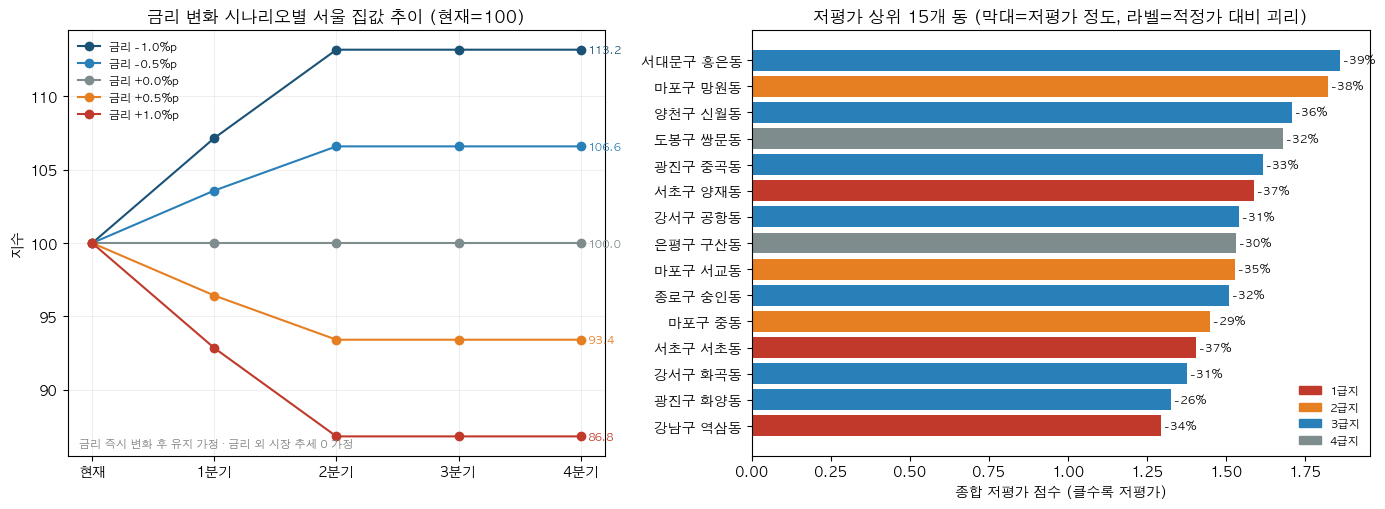

In [13]:
import matplotlib.pyplot as plt
from matplotlib import font_manager
for font in ['AppleGothic', 'Malgun Gothic', 'NanumGothic']:
    if font in {f.name for f in font_manager.fontManager.ttflist}:
        plt.rcParams['font.family'] = font
        break
plt.rcParams['axes.unicode_minus'] = False

def lag_eff(row, lag):
    w = {lag: 1.0}
    for kk in (2, 3, 4): w[f'{lag}_급지{kk}'] = float(row['급지'] == kk)
    w[f'{lag}_학원가'] = row['학원가']; w[f'{lag}_통근z'] = zc[row.name]
    return float(rate_comb(w) @ br)
e0 = np.average(base.apply(lambda r: lag_eff(r, 'dr0'), axis=1), weights=base['n'])
e1 = np.average(base.apply(lambda r: lag_eff(r, 'dr1'), axis=1), weights=base['n'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={'width_ratios': [1, 1.15]})
ax = axes[0]
x = np.arange(5)
for d, c in [(-1.0, '#1a5276'), (-0.5, '#2980b9'), (0.0, '#7f8c8d'), (0.5, '#e67e22'), (1.0, '#c0392b')]:
    path = np.array([0, e0*d, (e0+e1)*d, (e0+e1)*d, (e0+e1)*d])
    ax.plot(x, 100*(1+path/100), marker='o', color=c, label=f'금리 {d:+.1f}%p')
    ax.annotate(f'{100*(1+path[-1]/100):.1f}', (4, 100*(1+path[-1]/100)), xytext=(5, 0), textcoords='offset points', va='center', fontsize=8, color=c)
ax.set_xticks(x); ax.set_xticklabels(['현재', '1분기', '2분기', '3분기', '4분기'])
ax.set(title='금리 변화 시나리오별 서울 집값 추이 (현재=100)', ylabel='지수')
ax.grid(alpha=.2); ax.legend(frameon=False, fontsize=8)
ax.text(.02, .02, '금리 즉시 변화 후 유지 가정 · 금리 외 시장 추세 0 가정', transform=ax.transAxes, fontsize=8, color='gray')

ax = axes[1]
top = res.sort_values('종합z').head(15).iloc[::-1]
colors = {1: '#c0392b', 2: '#e67e22', 3: '#2980b9', 4: '#7f8c8d'}
bars = ax.barh(top['구'] + ' ' + top['동'], -top['종합z'], color=[colors[k] for k in top['급지']])
for b_, v in zip(bars, top['괴리_%']): ax.text(b_.get_width(), b_.get_y() + b_.get_height()/2, f' {v:.0f}%', va='center', fontsize=8)
ax.set(title='저평가 상위 15개 동 (막대=저평가 정도, 라벨=적정가 대비 괴리)', xlabel='종합 저평가 점수 (클수록 저평가)')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()], labels=[f'{k}급지' for k in colors], frameon=False, fontsize=8, loc='lower right')
fig.tight_layout(); plt.show()